In [1]:
import numpy as np
import os

In [2]:
import matplotlib.pyplot as plt

In [3]:
def open_snapshot(path, nx=520, ny=270, n_snapshots=50):
    data = np.fromfile(path, dtype=np.float32)
    snapshots = data.reshape(n_snapshots, nx, ny)
    snapshots = snapshots.T

    return snapshots

In [97]:
filename_exp_homo = "Exp_radiation_pattern/Exp1_all_homo_models/snap/pressure_wavefield.bin.p"
filename_exp_vp = "Exp_radiation_pattern/Exp2_disp_vp/snap/pressure_wavefield.bin.p"
# filename_exp_vs = "Exp_radiation_pattern/Exp3_disp_vs/snap/pressure_wavefield.bin.p"
filename_exp_vs = "/export/home/andres/DENISE-Black-Edition/par/snap/pressure_wavefield.bin.p"


filename_exp_rho = "Exp_radiation_pattern/Exp4_disp_rho/snap/pressure_wavefield.bin.p"

# print("Tamaño del archivo:", os.path.getsize(filename), "bytes")
# print("Número de valores:", data.size)
# print("Valores esperados:", n_snapshots * ny * nx)

In [98]:
snapshots_exp_homo = open_snapshot(path=filename_exp_homo, nx=520, ny=270, n_snapshots=50)
snapshots_exp_vp = open_snapshot(path=filename_exp_vp, nx=520, ny=270, n_snapshots=50)
snapshots_exp_vs = open_snapshot(path=filename_exp_vs, nx=520, ny=270, n_snapshots=50)
snapshots_exp_rho = open_snapshot(path=filename_exp_rho, nx=520, ny=270, n_snapshots=50)

In [99]:
# if data.size == n_snapshots * ny * nx:
#     snapshots = data.reshape(n_snapshots, nx, ny)
#     snapshots = snapshots.T

#     for k in [0, 1, 10, 25, 49]:
#         P = snapshots[k]
#         t = 0.002 + 0.06 * k

#         print(
#             f"k={k}, t={t:.3f} s, "
#             f"min={P.min():.6e}, max={P.max():.6e}, "
#             f"no ceros={np.count_nonzero(P)}"
#         )
# else:
#     print("El tamaño no coincide: hay que comprobar el formato.")

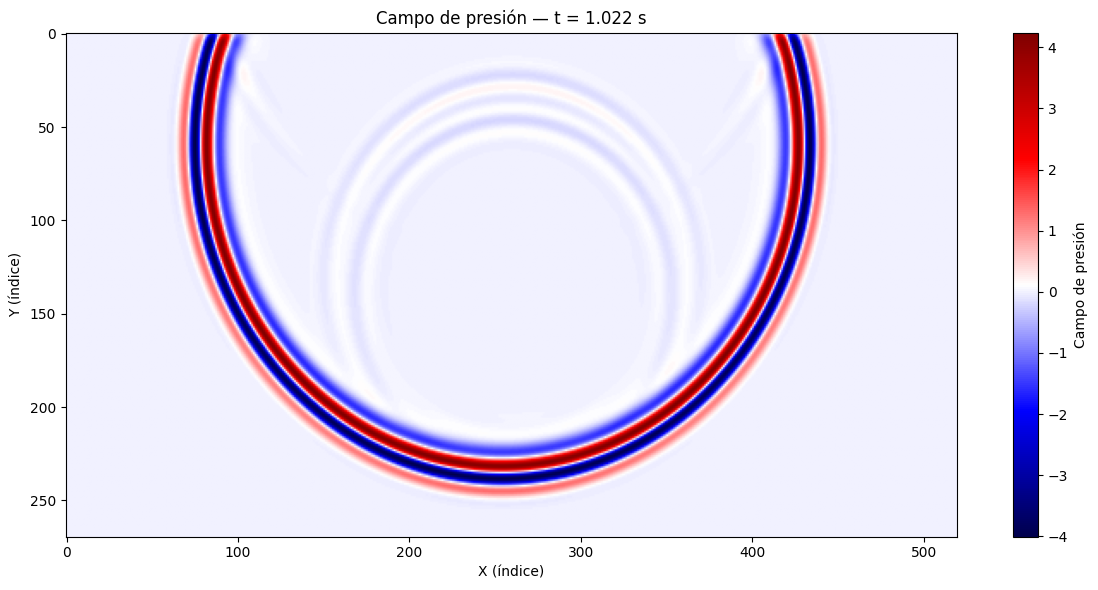

In [113]:
k = 17  # Cambia este índice para seleccionar otro instante

P = snapshots_exp_vs[:,:,k]
t = 0.002 + 0.06 * k

plt.figure(figsize=(12, 6))
plt.imshow(P, cmap="seismic", aspect="auto", origin="upper")
plt.colorbar(label="Campo de presión")
plt.title(f"Campo de presión — t = {t:.3f} s")
plt.xlabel("X (índice)")
plt.ylabel("Y (índice)")
plt.tight_layout()
plt.show()

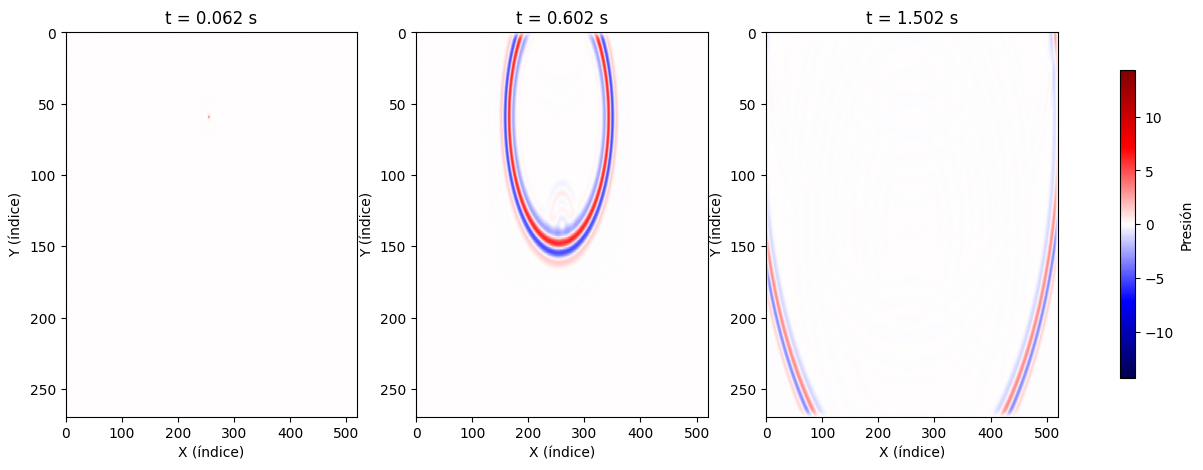

In [101]:
indices = [1, 10, 25]
clip = 14.32142

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, k in zip(axes, indices):
    P = snapshots_exp_vs[:,:,k]
    t = 0.002 + 0.06 * k

    im = ax.imshow(
        P,
        cmap="seismic",
        aspect="auto",
        origin="upper",
        vmin=-clip,
        vmax=clip
    )

    ax.set_title(f"t = {t:.3f} s")
    ax.set_xlabel("X (índice)")
    ax.set_ylabel("Y (índice)")

fig.colorbar(im, ax=axes, label="Presión", shrink=0.8)
# plt.tight_layout()
plt.show()

In [114]:
k = 17  # Cambia este índice para seleccionar otro instante

snap_exp1 = snapshots_exp_homo[:,:,k]
snap_exp2 = snapshots_exp_vp[:,:,k]
snap_exp3 = snapshots_exp_vs[:,:,k]
snap_exp4 = snapshots_exp_rho[:,:,k]

radiation_vp = snap_exp2 - snap_exp1
radiation_vs = snap_exp3 - snap_exp1
radiation_rho = snap_exp4 - snap_exp1

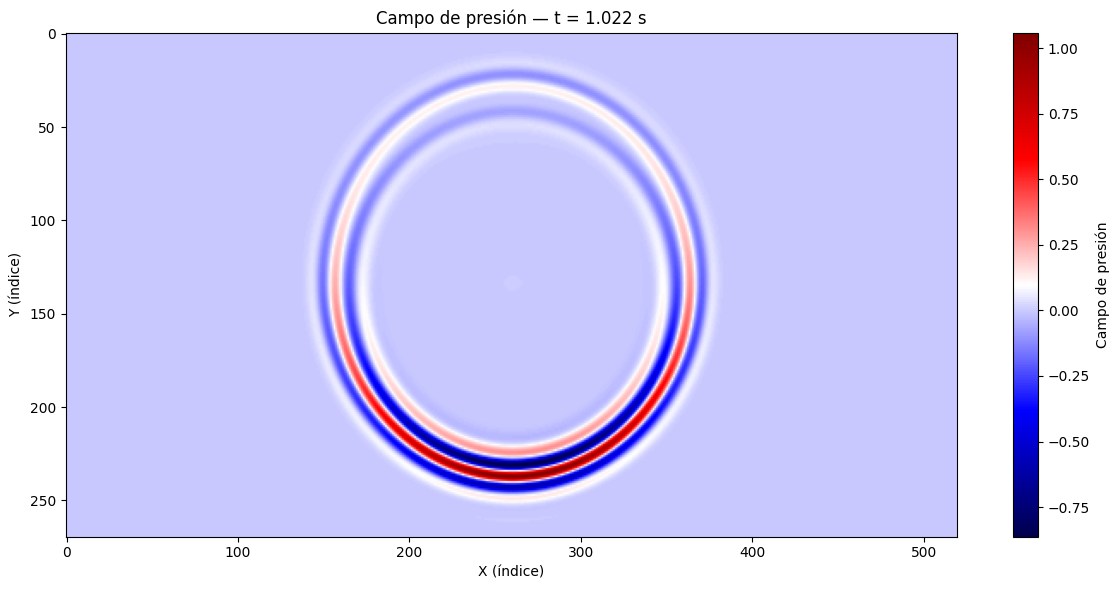

In [115]:
# k = 15  # Cambia este índice para seleccionar otro instante

# P = snapshots_exp_homo[:,:,k]
t = 0.002 + 0.06 * k

plt.figure(figsize=(12, 6))
plt.imshow(radiation_vp, cmap="seismic", aspect="auto", origin="upper")
plt.colorbar(label="Campo de presión")
plt.title(f"Campo de presión — t = {t:.3f} s")
plt.xlabel("X (índice)")
plt.ylabel("Y (índice)")
plt.tight_layout()
plt.show()

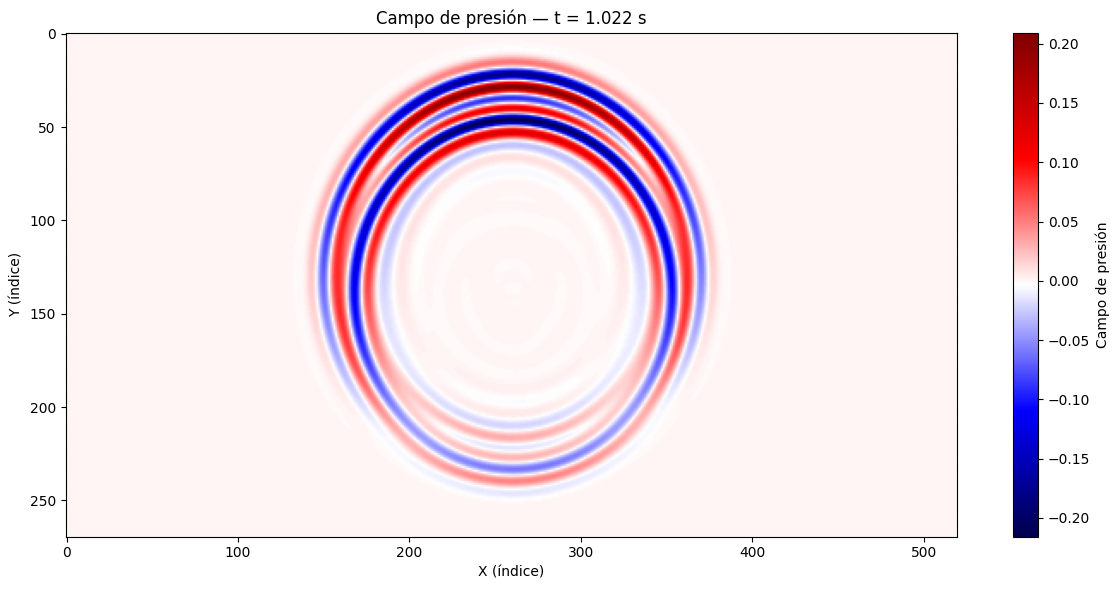

In [116]:
# k = 15  # Cambia este índice para seleccionar otro instante

# P = snapshots_exp_homo[:,:,k]
t = 0.002 + 0.06 * k

plt.figure(figsize=(12, 6))
plt.imshow(radiation_vs, cmap="seismic", aspect="auto", origin="upper")
plt.colorbar(label="Campo de presión")
plt.title(f"Campo de presión — t = {t:.3f} s")
plt.xlabel("X (índice)")
plt.ylabel("Y (índice)")
plt.tight_layout()
plt.show()

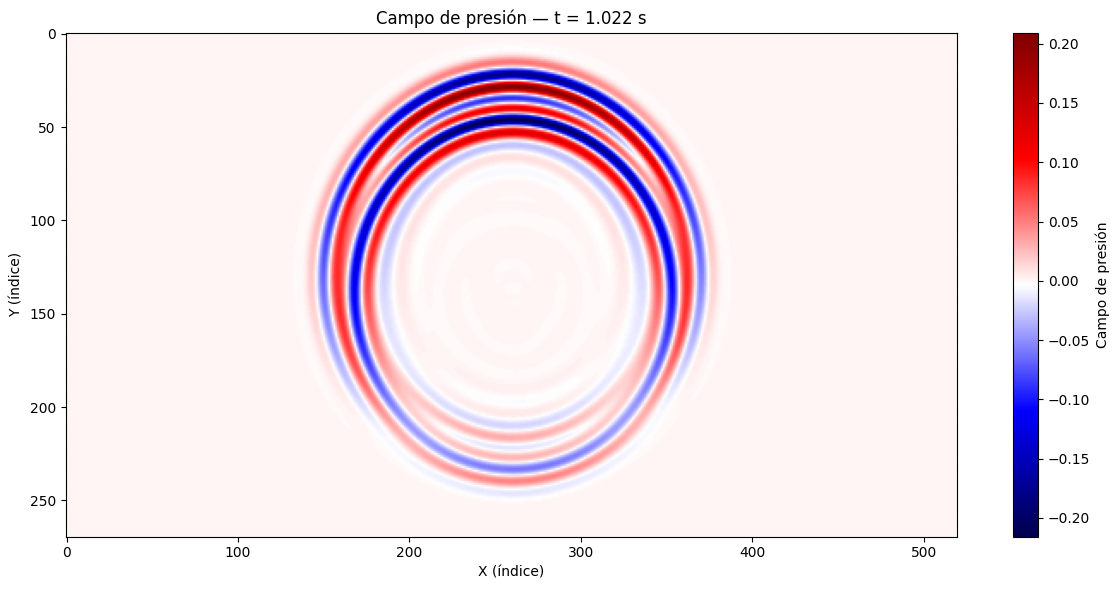

In [117]:
# k = 15  # Cambia este índice para seleccionar otro instante

# P = snapshots_exp_homo[:,:,k]
t = 0.002 + 0.06 * k

plt.figure(figsize=(12, 6))
plt.imshow(radiation_rho, cmap="seismic", aspect="auto", origin="upper")
plt.colorbar(label="Campo de presión")
plt.title(f"Campo de presión — t = {t:.3f} s")
plt.xlabel("X (índice)")
plt.ylabel("Y (índice)")
plt.tight_layout()
plt.show()

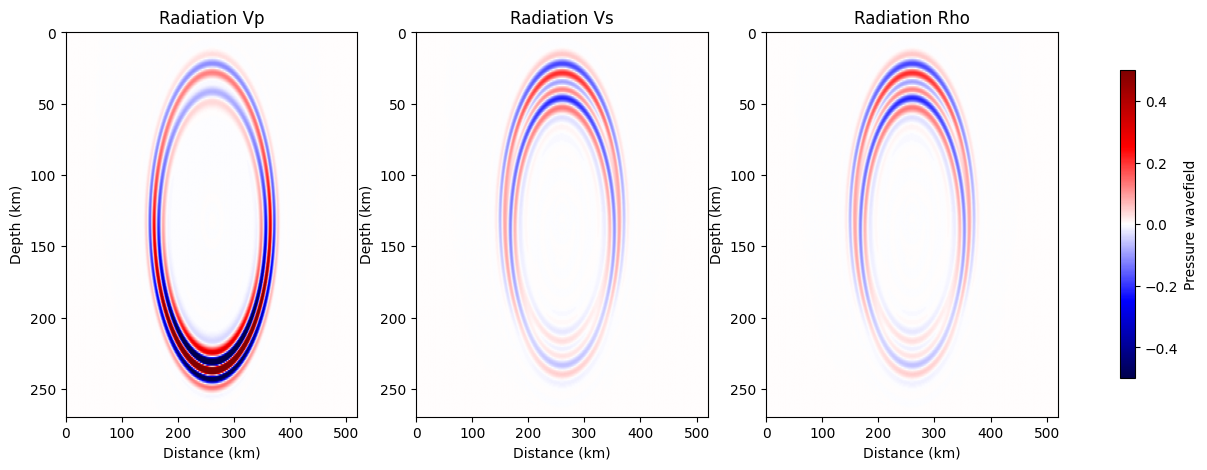

In [121]:
experimentos = [radiation_vp, radiation_vs, radiation_rho]
titulos = ["Radiation Vp", "Radiation Vs", "Radiation Rho"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, experimento, titulo in zip(axes, experimentos, titulos):

    im = ax.imshow(
        experimento,
        cmap="seismic",
        aspect="auto",
        origin="upper",
        vmin= -0.5, vmax=0.5
    )

    ax.set_title(titulo)
    ax.set_xlabel("Distance (km)")
    ax.set_ylabel("Depth (km)")

fig.colorbar(im, ax=axes, label="Pressure wavefield", shrink=0.8)
# plt.tight_layout()
# plt.savefig('radiation_pattern2.pdf')

plt.show()